# Image artifacts: does uncertainty react?

One question only: when the slide degrades (blur, salt-and-pepper), **does the model's uncertainty rise?**

| quantity | where it comes from | what it says |
|---|---|---|
| `d_mean` (kNN) | `knn_uncertainty_precompute.py --stage ood_corruption` | does the corrupted embedding move away from the training cloud (= OOD) |
| `d_norm` (kNN) | same, divided by the radius of the spot's cluster | the same thing **de-confounded from tissue-type rarity**. The divisor is frozen on the clean embedding, so it is constant in severity: in ratio-to-clean, `d_norm` lies on top of `d_mean` by construction, and it is read in absolute value rather than as a slope |
| aleatoric | variance head of the heteroscedastic Gaussian | the uncertainty the model assigns itself on the noise |
| epistemic | disagreement between draws (MC-dropout) or between members (deep ensemble) | model uncertainty |

The control is `|residual|`: if the error rises and the uncertainty does not move, the uncertainty does not detect the artifact.

Five sections: **1** what the artifacts look like, **3** the aggregated dose-response, **4** where the embeddings go (2d projection + Leiden clusters), **5** the figure of the paper on one cohort, **6** the same curves on the three cohorts.

Everything is on the **log1p-CP10k** axis (Gaussian only), so no `depth_scale` / g* story here. The severity 0 point is `adata.obsm["X_emb"]`, that is, exactly the training embeddings.

## 0. Config

In [ ]:
import sys
import pathlib; sys.path.append(str(next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / 'src').is_dir())))  # parent dir of src

import glob, json, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())

DATASETS   = ['10x_TuPro', 'TLS', 'LUNG_CANCER']
MC_RUN_ID  = 'pr_classic3'      # single model -> MC-dropout
ENS_RUN_ID = 'de_6'             # paired deep ensemble
MODEL_TYPE = 'heteroscedastic'
LAM_DIR    = 'lambda_0.0'       # lambda_ segment of the SINGLE run only (absent from the ensemble path)
RADIUS     = 'r75'
GENE_SET   = lambda ds: f'_{ds}_hvg_top3000'

# A run's outputs can live under a per-run results root.
MC_ROOT  = PROJ / 'results'
ENS_ROOT = PROJ / 'results'
KNN_ROOT = PROJ / 'results' / '_analysis' / 'knn_uncertainty'
FIGDIR   = PROJ / 'results' / '_analysis' / 'figures'
FIGDIR.mkdir(parents=True, exist_ok=True)

# Corruption families. key = the label written by artifact_uncertainty_precompute.py;
# knn_variant = the label written by knn_uncertainty_precompute.py for the SAME thing.
FAMILIES = [
    ('blur',              'Gaussian blur',            None,        'blur_factor'),
    ('saltpepper_sp1-1',  'Salt-and-pepper, 1 px',    'monopixel', 'amount'),
    ('saltpepper_sp2-4',  'Salt-and-pepper, 2-4 px',  'dust_2-4',  'amount'),
]

# The text INSIDE the figures is English (they go as-is into the LaTeX);

DATASET_LABELS = {'10x_TuPro': 'Tumor Profiler', 'TLS': 'Kidney/Lung with TLS',
                  'LUNG_CANCER': 'NSCLC'}
METHOD_LABELS  = {'mc': 'MC-dropout', 'ensemble': 'deep ensemble', 'knn': 'kNN'}
QLABEL = {'aleatoric_mean': 'aleatoric', 'epistemic_mean': 'epistemic',
          'abs_resid_mean': '|residual|', 'd_mean': 'kNN distance', 'd_norm': 'kNN distance / cluster radius'}

# Color = quantity (one color = one quantity everywhere), line style = method.
QCOLOR = {'d_mean': '#7f7f7f', 'd_norm': '#9467bd', 'aleatoric_mean': '#1f77b4',
          'epistemic_mean': '#d62728', 'abs_resid_mean': '#000000'}
MSTYLE = {'mc': '-', 'ensemble': '--', 'knn': ':'}

print('figures ->', FIGDIR.relative_to(PROJ))
print(f'{len(FAMILIES)} artifact families x {len(DATASETS)} cohorts x 2 methods')

figures -> results/_analysis/figures
3 artifact families x 3 cohorts x 2 methods


## 1. What the artifacts look like

A single spot, the same extraction recipe as the jobs: the blur is Gaussian with `sigma = bf * spot_diameter_fullres` (so the same *physical* extent on every slide), the salt-and-pepper is applied to the model's 224 input (after resize), with specks of 1 px (single-pixel) or 2 to 4 px (dust).

One approximation only, purely visual: the blur is applied to a wide window around the spot rather than to the whole slide (identical at the center, and it avoids blurring 17k x 17k px for one figure).

/cluster/customapps/biomed/grlab/users/tbatique/conda/envs/mtenv0/lib/python3.13/site-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


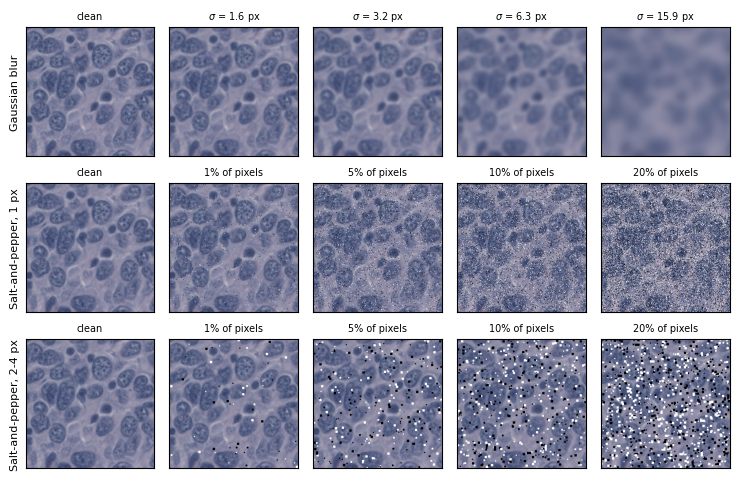

saved -> fig_artifact_illustration.pdf (+ .png)
TITLE (to put in the LaTeX caption, not in the figure):
  The two image artifacts, at every severity level, on one Visium spot (MAJOFIJ-1-1, spot 2050). Blur is applied to the whole slide before cropping, with sigma proportional to the spot diameter; salt-and-pepper is applied to the model's 224x224 input.

spot_diam = 317.0 px, crop radius = 238 px
sigma (px) per blur_factor: {0.0: 0.0, 0.005: 1.58, 0.01: 3.17, 0.02: 6.34, 0.05: 15.85}


In [ ]:
import scanpy as sc
from PIL import Image
from scipy.ndimage import gaussian_filter
from torchvision.transforms import v2
from src.embedding_extraction.patch_embed_extraction import (
    build_transform, apply_salt_pepper, _crop_spot_patch)

Image.MAX_IMAGE_PIXELS = None

# Illustration slide + spot (TuPro; same paths as extract_saltpepper_embeddings.py).
import yaml
_CFG = yaml.safe_load(open(PROJ / 'snake' / 'config' / 'config.yaml'))
ILLU = dict(parent=_CFG['datasets']['10x_TuPro']['parent_dir'],
            slide='MAJOFIJ-1-1', spot=2050, radius_factor=0.75, swap_xy=True)
BLUR_LEVELS = [0.0, 0.005, 0.01, 0.02, 0.05]
SP_LEVELS   = [0.0, 0.01, 0.05, 0.1, 0.2]

meta = json.load(open(f"{ILLU['parent']}meta/{ILLU['slide']}.json"))
spot_diam = meta['spot_diameter_fullres']
radius    = int(round(spot_diam * ILLU['radius_factor']))
cdata     = sc.read_h5ad(f"{ILLU['parent']}h5ad/{ILLU['slide']}.h5ad")
cy, cx    = cdata.obs[['x_pixel', 'y_pixel']].to_numpy()[ILLU['spot']]  # swap_xy: (row, col)
img       = np.array(Image.open(f"{ILLU['parent']}image/{ILLU['slide']}.tif"))
H, W      = img.shape[:2]

# Wide window (4x the patch): the blur is applied to it, then we crop to the center.
pad  = 4 * radius
y0, y1 = max(0, int(cy) - pad), min(H, int(cy) + pad)
x0, x1 = max(0, int(cx) - pad), min(W, int(cx) + pad)
win  = img[y0:y1, x0:x1].copy()
wcy, wcx = int(cy) - y0, int(cx) - x0
del img

resize_crop = v2.Compose(list(build_transform().transforms)[:-2])   # resize + center-crop, without ToTensor/Normalize

def patch224(win_img):
    p = _crop_spot_patch(win_img, wcx, wcy, radius, win_img.shape[1], win_img.shape[0])
    return np.asarray(resize_crop(Image.fromarray(p)))

clean224 = patch224(win)          # the clean patch, computed ONCE (invariant to salt-pepper levels)

rows = [('Gaussian blur', BLUR_LEVELS, None),
        ('Salt-and-pepper, 1 px', SP_LEVELS, (1, 1)),
        ('Salt-and-pepper, 2-4 px', SP_LEVELS, (2, 4))]
fig, axes = plt.subplots(3, 5, figsize=(7.5, 4.9))
for r, (name, levels, speck) in enumerate(rows):
    for c, lev in enumerate(levels):
        if speck is None:                       # blur: on the window, before cropping
            w = win.copy()
            if lev > 0:
                for ch in range(3):
                    w[..., ch] = np.clip(gaussian_filter(win[..., ch].astype(np.float32),
                                                         sigma=lev * spot_diam), 0, 255).astype(np.uint8)
            p   = patch224(w)
            lbl = 'clean' if lev == 0 else f'$\\sigma$ = {lev * spot_diam:.1f} px'
        else:                                    # salt-and-pepper: on the 224, as at extraction
            p = clean224.copy()
            if lev > 0:
                apply_salt_pepper(p, lev, 0.5, np.random.default_rng((0, ILLU['spot'])),
                                  speck_min=speck[0], speck_max=speck[1])
            lbl = 'clean' if lev == 0 else f'{lev:.0%} of pixels'
        ax = axes[r, c]
        ax.imshow(p); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(lbl, fontsize=7)
    axes[r, 0].set_ylabel(name, fontsize=8)
fig.tight_layout()
stem = 'fig_artifact_illustration'
for ext in ('pdf', 'png'):
    fig.savefig(FIGDIR / f'{stem}.{ext}', bbox_inches='tight', dpi=200)
plt.show()

print(f'saved -> {stem}.pdf (+ .png)')
print('TITLE (to put in the LaTeX caption, not in the figure):')
print('  The two image artifacts, at every severity level, on one Visium spot '
      f"({ILLU['slide']}, spot {ILLU['spot']}). Blur is applied to the whole slide before "
      'cropping, with sigma proportional to the spot diameter; salt-and-pepper is applied to '
      "the model's 224x224 input.")
print(f'\nspot_diam = {spot_diam:.1f} px, crop radius = {radius} px')
print('sigma (px) per blur_factor:', {bf: round(bf * spot_diam, 2) for bf in BLUR_LEVELS})

## 2. Loading the precomputes

Nothing is recomputed here. Two sources:

- `artifact_uncertainty_precompute.py` writes **three views of the same matrices**, reduced on the GPU: `artifact_uncertainty.parquet` (per corruption x severity x donor), `..._per_spot.parquet` (one value per spot, averaged over genes) and `..._per_gene.parquet` (one value per gene, averaged over spots). Sections 3, 5 and 6 read these three views respectively.
- `knn_uncertainty_precompute.py --stage ood_corruption` writes `{blur,saltpepper}_distance_by_k.parquet`, one row per (spot, severity, k), with `d_mean`, `d_norm` and the cluster label per scheme.

In [ ]:
def run_leaf(ds, method):
    """The scored run's directory: the SINGLE run has a lambda_ segment, the ensemble does not."""
    if method == 'mc':
        return MC_ROOT / ds / MC_RUN_ID / GENE_SET(ds) / RADIUS / MODEL_TYPE / LAM_DIR
    return ENS_ROOT / ds / ENS_RUN_ID / GENE_SET(ds) / RADIUS / MODEL_TYPE

def load_per(view, methods=('mc', 'ensemble'), verbose=True):
    """Loads one of the three views written by artifact_uncertainty_precompute.py:
    view='agg' (per corruption x severity x donor), 'per_spot' or 'per_gene'."""
    fname = {'agg': 'artifact_uncertainty.parquet',
             'per_spot': 'artifact_uncertainty_per_spot.parquet',
             'per_gene': 'artifact_uncertainty_per_gene.parquet'}[view]
    parts = []
    for ds in DATASETS:
        for method in methods:
            p = run_leaf(ds, method) / 'artifact_uncertainty' / fname
            if p.exists():
                parts.append(pd.read_parquet(p))
            elif verbose:
                print('MISSING:', p)
    if not parts:
        return pd.DataFrame()
    t = pd.concat(parts, ignore_index=True)
    # The precompute encodes the text columns as `category` so the file stays small;
    # we go back to str here, otherwise each groupby produces the cartesian product of the categories.
    for c in t.columns:
        if str(t[c].dtype) == 'category':
            t[c] = t[c].astype(str)
    return t

# ── The kNN run_tag, explicit and NEVER globbed ───────────────────────────────
# launch_knn_uncertainty_precompute.sh named its folders
# <dataset>/<run_id>__<gene_set>__<radius>__<model_type>__<lambda_dir>/donor=<donor>/.
# Globbing this level with `*` would mix several runs (another run_id sitting next to
# pr_classic3) and would count donors twice: the tag is therefore rebuilt
# from the same constants as the rest of the notebook, with a flagged fallback if absent.
def knn_tag(ds):
    return f'{MC_RUN_ID}__{GENE_SET(ds)}__{RADIUS}__{MODEL_TYPE}__{LAM_DIR}'

def knn_donor_dirs(ds, sub=''):
    """The donor=<...>[/<sub>] directories of the analyzed run, for one cohort."""
    exact = sorted(glob.glob(f'{KNN_ROOT}/{ds}/{knn_tag(ds)}/donor=*' + (f'/{sub}' if sub else '')))
    if exact:
        return exact
    other = sorted({p.split(f'{ds}/')[1].split('/')[0]
                    for p in glob.glob(f'{KNN_ROOT}/{ds}/*/donor=*')})
    if other:
        print(f'WARNING {ds}: no kNN under the expected run_tag\n  {knn_tag(ds)}\n'
              f'  tags present: {other}\n  -> nothing loaded for this cohort (fix '
              f'MC_RUN_ID / MODEL_TYPE / LAM_DIR, or rerun the kNN precompute on this run).')
    return []

# ── The three kNN distances, and which one to read when ───────────────────────
#   d_mean        mean distance to the k nearest neighbors of the reference pool (donor
#                 excluded). The RAW quantity, with no clustering assumption, hence the only
#                 one directly comparable across cohorts.
#   d_norm        d_mean divided by the radius of the spot's cluster -> de-confounds TISSUE
#                 TYPE rarity. BUT this column aliases the PRIMARY scheme of each cohort, which
#                 differs (gt on TuPro, imputed gt on TLS, leiden on NSCLC): its magnitudes do
#                 not compare from one cohort to another.
#   d_norm_leiden the same index, but with the leiden scheme EVERYWHERE -- the only one available
#                 on all three cohorts, so the d_norm to use whenever cohorts are put side by side.
# When to use what: the divisor being CONSTANT in severity (assignment frozen on the clean
# embedding), in ratio-to-clean (section 3) d_norm lies on top of d_mean by construction -> so we
# plot d_mean. It is PER SPOT (section 5) that the division changes the spot ranking, and there
# that d_norm is the right signal.
KNN_SIGNALS = ['d_mean', 'd_norm', 'd_norm_leiden']

def load_knn_spots(fam):
    """The PER-SPOT kNN distances (not averaged) for one corruption family. The d_norm_<scheme>
    columns missing from a cohort are simply ignored (LUNG_CANCER has no
    ground_truth, hence no d_norm_gt) -- a missing scheme is a skipped scheme, not an error."""
    _, _, knn_variant, sev_col = next(f for f in FAMILIES if f[0] == fam)
    parts = []
    for ds in DATASETS:
        for d in knn_donor_dirs(ds, 'ood_corruption'):
            smry = os.path.join(d, 'summary.json')
            kh   = json.load(open(smry))['k_headline'] if os.path.exists(smry) else 25
            f    = os.path.join(d, ('blur' if knn_variant is None else 'saltpepper') + '_distance_by_k.parquet')
            if not os.path.exists(f):
                continue
            t = pd.read_parquet(f)                      # short file (sampled spots x severities x k)
            t = t[t['k'] == kh]
            if knn_variant is not None:
                t = t[t['variant'] == knn_variant]
            keep = ['obs_name', 'slide'] + [c for c in KNN_SIGNALS if c in t.columns]
            t = t[keep + [sev_col]].rename(columns={sev_col: 'severity'})
            t['dataset'], t['test_donor'] = ds, d.replace(os.sep, '/').split('donor=')[1].split('/')[0]
            parts.append(t)
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()

# ── aggregated uncertainty (aleatoric / epistemic / residual), MC-dropout + deep ensemble ──
unc = load_per('agg')
print('uncertainty:', len(unc), 'rows |',
      unc.groupby(['dataset', 'method']).size().to_dict() if len(unc) else '-')

# ── kNN distances, averaged over spots then kept per donor ────────────────────
knn = []
for fam, _, _, _ in FAMILIES:
    t = load_knn_spots(fam)
    if len(t) == 0:
        continue
    sig = [c for c in KNN_SIGNALS if c in t.columns]
    g = t.groupby(['dataset', 'test_donor', 'severity'])[sig].mean().reset_index()
    g['corruption'] = fam
    knn.append(g)
knn = pd.concat(knn, ignore_index=True) if knn else pd.DataFrame()
print('kNN:', len(knn), 'rows |',
      'donors per cohort:', knn.groupby('dataset')['test_donor'].nunique().to_dict() if len(knn) else '-',
      '| signals :', [c for c in KNN_SIGNALS if c in knn.columns] if len(knn) else '-')
print('kNN run_tag used:', {ds: knn_tag(ds) for ds in DATASETS})

uncertainty: 630 rows | {('10x_TuPro', 'ensemble'): 105, ('10x_TuPro', 'mc'): 105, ('LUNG_CANCER', 'ensemble'): 120, ('LUNG_CANCER', 'mc'): 120, ('TLS', 'ensemble'): 90, ('TLS', 'mc'): 90}
kNN: 315 rows | donors per cohort: {'10x_TuPro': 7, 'LUNG_CANCER': 8, 'TLS': 6} | signals : ['d_mean', 'd_norm', 'd_norm_leiden']
kNN run_tag used: {'10x_TuPro': 'pr_classic3___10x_TuPro_hvg_top3000__r75__heteroscedastic__lambda_0.0', 'TLS': 'pr_classic3___TLS_hvg_top3000__r75__heteroscedastic__lambda_0.0', 'LUNG_CANCER': 'pr_classic3___LUNG_CANCER_hvg_top3000__r75__heteroscedastic__lambda_0.0'}


## 3. Dose-response

Each curve is **normalized to its own clean value** (severity 0), so `1.0` = "did not move". The mean is taken over donors (each donor = one LOPO fold, tested by the model that never saw it).

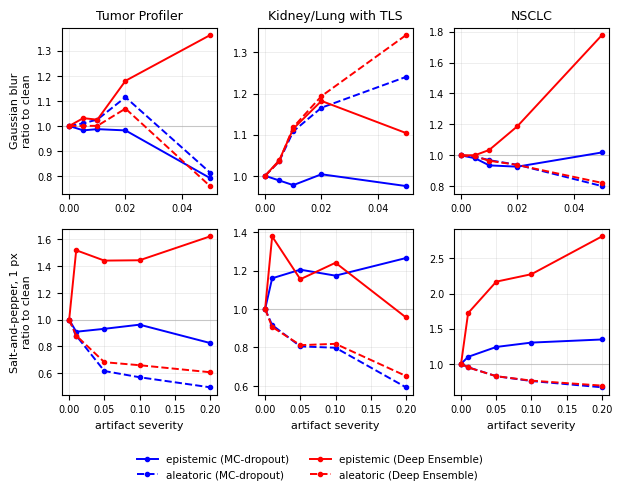

saved -> fig_artifact_uncertainty.pdf (+ .png)
TITLE (LaTeX caption): Predicted uncertainty against artifact severity, each curve divided by its own clean value and averaged over held-out donors. Solid, epistemic; dashed, aleatoric.



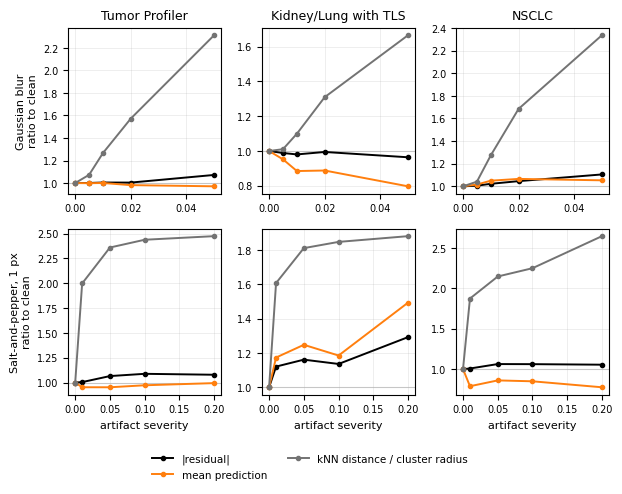

saved -> fig_artifact_context.pdf (+ .png)
TITLE (LaTeX caption): The same spots under the same severities: distance to the training pool, absolute error, and mean prediction, each divided by its clean value.

----------------------------------------------------------------------------------------------------
GAUSSIAN BLUR -- RATIO to the clean value (1.0 = did not move)
----------------------------------------------------------------------------------------------------
severity                             0.000  0.005  0.010  0.020  0.050
dataset     method   quantity                                         
10x_TuPro   ensemble aleatoric_mean    1.0  1.000  1.001  1.069  0.760
                     epistemic_mean    1.0  1.031  1.025  1.180  1.362
            knn      d_norm_leiden     1.0  1.073  1.267  1.572  2.313
            mc       abs_resid_mean    1.0  1.001  1.005  1.004  1.072
                     aleatoric_mean    1.0  1.011  1.025  1.115  0.814
                     epistem

In [ ]:
# COLOR ENCODES THE ESTIMATOR, canonically: MC-dropout 'b',
# Deep Ensemble 'r' (saturated matplotlib base colors). The quantity is therefore carried by the
# LINE STYLE, never by the color.
METHOD_COLORS = {'mc': 'b', 'ensemble': 'r'}
METHOD_LABELS = {'mc': 'MC-dropout', 'ensemble': 'Deep Ensemble', 'knn': 'kNN'}

# Two families in the body figures. The 2-4 px variant stays in the printed tables.
FAMS_FIG = ['blur', 'saltpepper_sp1-1']
# NORMALIZED kNN distance, leiden scheme: the only one available on all three cohorts. The
# divisor is the cluster radius, that is, the mean distance of its members to their
# centroid, frozen on the clean embedding.
KNN_SIG = 'd_norm_leiden' if (len(knn) and 'd_norm_leiden' in knn.columns) else 'd_mean'
QLABEL.update({'pred_mean': 'mean prediction',
               'd_norm_leiden': 'kNN distance / cluster radius'})

def ratio_curve(df, value_col):
    """Mean over donors, then ratio to severity 0 (a CONSTANT per curve)."""
    g = df.groupby('severity')[value_col].mean().reset_index()
    g.columns = ['severity', 'value']
    g = g.sort_values('severity')
    base = g.loc[g['severity'] == 0.0, 'value']
    if base.empty or float(base.iloc[0]) == 0.0:
        return None
    g['ratio'] = g['value'] / float(base.iloc[0])
    return g

def draw(fig_kind):
    """Two figures, same grid: rows = artifact families, columns = cohorts.
    'uncertainty' carries the answer to the question, epistemic and aleatoric for both
    methods. 'context' carries what is needed to read it: input shift, error, predicted
    mean. Splitting them keeps each figure at 6 panels and 3 or 4 curves."""
    fig, axes = plt.subplots(len(FAMS_FIG), len(DATASETS),
                             figsize=(6.3, 2.0 * len(FAMS_FIG) + 0.9), squeeze=False)
    tab = []
    for r, fam in enumerate(FAMS_FIG):
        fam_label = next(f[1] for f in FAMILIES if f[0] == fam)
        for c, ds in enumerate(DATASETS):
            ax, curves = axes[r][c], []
            if fig_kind == 'uncertainty':
                for method in ('mc', 'ensemble'):
                    sub = unc[(unc['dataset'] == ds) & (unc['corruption'] == fam)
                              & (unc['method'] == method)] if len(unc) else pd.DataFrame()
                    if len(sub) == 0:
                        continue
                    # solid line = epistemic, dashes = aleatoric
                    curves += [(sub, 'epistemic_mean', METHOD_COLORS[method], '-', method),
                               (sub, 'aleatoric_mean', METHOD_COLORS[method], '--', method)]
            else:
                # One method is enough here: the error and the predicted mean differ by
                # less than 1 % between MC-dropout and the ensemble. MC-dropout is the one plotted.
                sub = unc[(unc['dataset'] == ds) & (unc['corruption'] == fam)
                          & (unc['method'] == 'mc')] if len(unc) else pd.DataFrame()
                if len(sub):
                    curves += [(sub, 'abs_resid_mean', 'k', '-', 'mc'),
                               (sub, 'pred_mean', '#ff7f0e', '-', 'mc')]
                ksub = knn[(knn['dataset'] == ds) & (knn['corruption'] == fam)] if len(knn) else pd.DataFrame()
                if len(ksub):
                    curves += [(ksub, KNN_SIG, '0.45', '-', 'knn')]
            for sub, col, color, ls, method in curves:
                g = ratio_curve(sub, col)
                if g is None:
                    continue
                lbl = (f'{QLABEL.get(col, col)} ({METHOD_LABELS[method]})'
                       if fig_kind == 'uncertainty' else QLABEL.get(col, col))
                ax.plot(g['severity'], g['ratio'], ls, color=color, marker='o', ms=3, lw=1.4,
                        label=lbl)
                tab.append(g.assign(dataset=ds, corruption=fam, method=method, quantity=col))
            ax.axhline(1.0, color='0.8', lw=0.8, zorder=0)
            ax.grid(alpha=0.25, lw=0.6)
            ax.tick_params(labelsize=7)
            if r == 0:
                ax.set_title(DATASET_LABELS[ds], fontsize=9)
            if c == 0:
                ax.set_ylabel(f'{fam_label}\nratio to clean', fontsize=8)
            if r == len(FAMS_FIG) - 1:
                ax.set_xlabel('artifact severity', fontsize=8)
    h, l = max((ax.get_legend_handles_labels() for row in axes for ax in row),
               key=lambda hl: len(hl[0]))
    fig.legend(h, l, loc='lower center', ncol=2, frameon=False, fontsize=7.5,
               bbox_to_anchor=(0.5, -0.01))
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    stem = f'fig_artifact_{fig_kind}'
    for ext in ('pdf', 'png'):
        fig.savefig(FIGDIR / f'{stem}.{ext}', bbox_inches='tight', dpi=300)
    plt.show()
    print(f'saved -> {stem}.pdf (+ .png)')
    return pd.concat(tab, ignore_index=True) if tab else pd.DataFrame()

T_unc = draw('uncertainty')
print('TITLE (LaTeX caption): Predicted uncertainty against artifact severity, each curve '
      'divided by its own clean value and averaged over held-out donors. Solid, epistemic; '
      'dashed, aleatoric.\n')
T_ctx = draw('context')
print('TITLE (LaTeX caption): The same spots under the same severities: distance to the '
      'training pool, absolute error, and mean prediction, each divided by its clean value.')

# ── The twin tables, on all THREE families ────────────────────────────────────
T = pd.concat([T_unc, T_ctx], ignore_index=True)
if len(T):
    for fam, fam_label, _, _ in FAMILIES:
        sub = T[T['corruption'] == fam]
        if sub.empty:
            continue
        print('\n' + '-' * 100)
        print(f"{fam_label.upper()} -- RATIO to the clean value (1.0 = did not move)")
        print('-' * 100)
        print(sub.pivot_table(index=['dataset', 'method', 'quantity'], columns='severity',
                              values='ratio').round(3).to_string())
    print('\n' + '-' * 100)
    print("RAW VALUES at clean (severity 0) -- the scale of the ratios above")
    print('-' * 100)
    print(T[T['severity'] == 0.0]
          .pivot_table(index=['dataset', 'method', 'quantity'], columns='corruption', values='value')
          .round(5).to_string())

# Pearson, pred_sd and the error-uncertainty correlation are NOT ratios: they are
# read as raw values. They only exist if the precompute was rerun.
RAW = [c for c in ('pearson', 'pred_sd', 'unc_err_spearman_gene')
       if len(unc) and c in unc.columns]
if RAW:
    print('\n' + '-' * 100)
    print('PERFORMANCE AND DISPERSION, raw value (pearson and error-uncertainty correlation:')
    print('one atom per (slide, gene), nanmean over slides, then over genes)')
    print('-' * 100)
    print(unc[unc['corruption'].isin(FAMS_FIG)]
          .groupby(['dataset', 'method', 'corruption', 'severity'])[RAW]
          .mean().round(4).to_string())
else:
    print('\npearson / pred_sd / unc_err_spearman_gene missing from the parquet: rerun the precompute.')

## 4. The drift plane: where does the held-out patient go?

Two figures, two linear axes, **no nonlinear embedding**.

**Why not t-SNE / UMAP.** What we want to show is a DISTANCE (the patient moves away from the training cloud), and neither t-SNE nor UMAP preserves distances or densities: they preserve the local neighborhood and reorganize the rest. They are therefore exactly the tools allowed to erase the effect we want to see. Three practical flaws on top: t-SNE has no `transform` (one would have to fit on the corrupted points themselves, which could then be absorbed into the cloud), the result depends on the perplexity and the seed, and the computation cannot be redone mentally. The very compact cloud we observed was not a tuning flaw: it is what a 3072-dimensional space gives when the variance is spread over many axes.

**Figure 1 -- the drift plane.** Two directions, each point placed by a simple dot product:
- **x = the artifact direction**, `u = normalize(mean(E_patient@severity_max) - mean(E_patient@clean))`;
- **y = the principal direction of the reference pool**, orthogonalized with respect to `u`.

Both axes are then **graduated in standard deviations of the reference pool** along themselves. The training cloud therefore has standard deviation 1 on both axes, the dotted circles mark 1 and 2 sigma, and "the patient went out to 3 sigma" reads straight off the figure. It is the same logic as `d_norm` (normalize by the pool's own dispersion), so one convention less to explain.

**The objection, and its answer.** Yes, the x axis is built from the corrupted data, so a drift is visible there by construction. What is NOT chosen is its **magnitude relative to the pool's dispersion** -- and that is the only thing we read. The proof itself does not come from the figure: it is `emb_shift`, the L2 displacement in the original 3072-dimensional space, printed below the figures and independent of any projection.

**Figure 2 -- the control.** The same spots on the pool's plain PCA (PC1/PC2), with no chosen direction. It shows what an unoriented projection lets one see, and its explained variance (printed to the left of each row) says right away whether a compact cloud is the CORRECT result rather than a figure defect.

The Leiden clusters are not recomputed: they are read back from the kNN precompute cache (`<donor>/leiden_labels.npz`), so it is exactly the partition that serves as the denominator of `d_norm`. L2-normalized embeddings (`L2NORM`), as everywhere in the kNN module. `N_REF` / `N_HELD` subsample, `FAM_MAP` switches blur / salt-and-pepper, `HELD_DONOR` forces a patient. Everything runs in the notebook in a few tens of seconds: PCA on 5000 x 3072, no cluster job.

10x_TuPro: held-out MACEGEJ | pool 5000 spots, 22 clusters Leiden | patient 1500 spots | 6s
TLS: held-out KC1 | pool 5000 spots, 26 clusters Leiden | patient 1500 spots | 2s
LUNG_CANCER: held-out P10 | pool 5000 spots, 20 clusters Leiden | patient 1500 spots | 16s


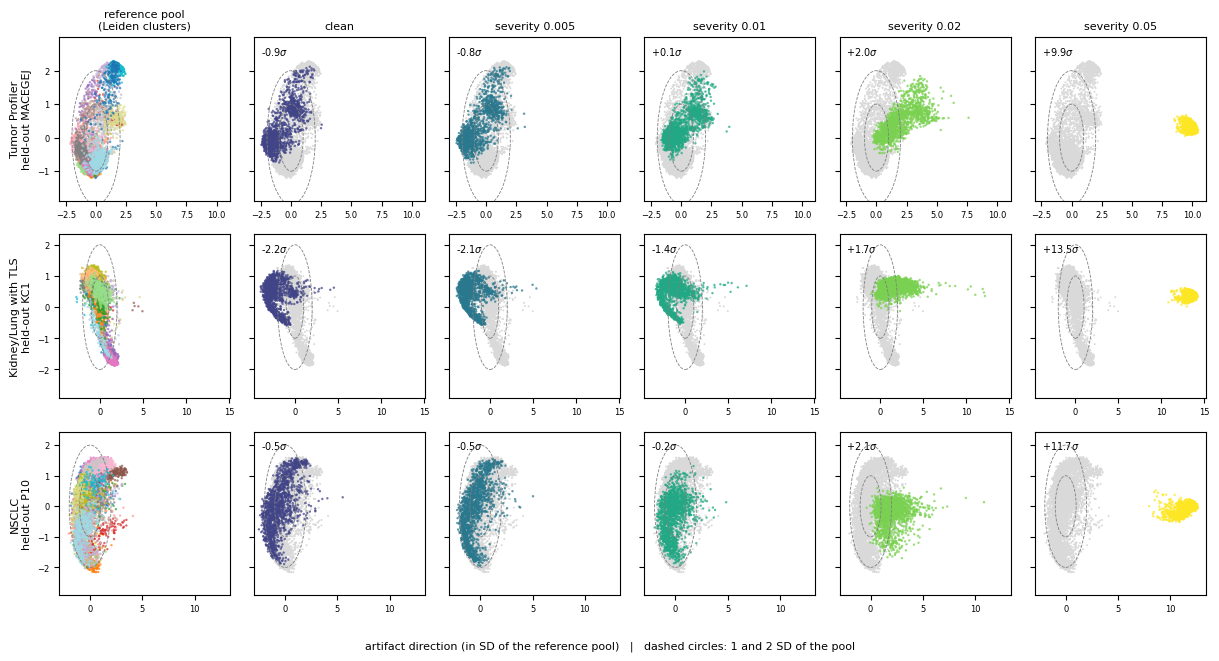

saved -> fig_artifact_drift_plane_blur.pdf (+ .png)   [Gaussian blur, drift]


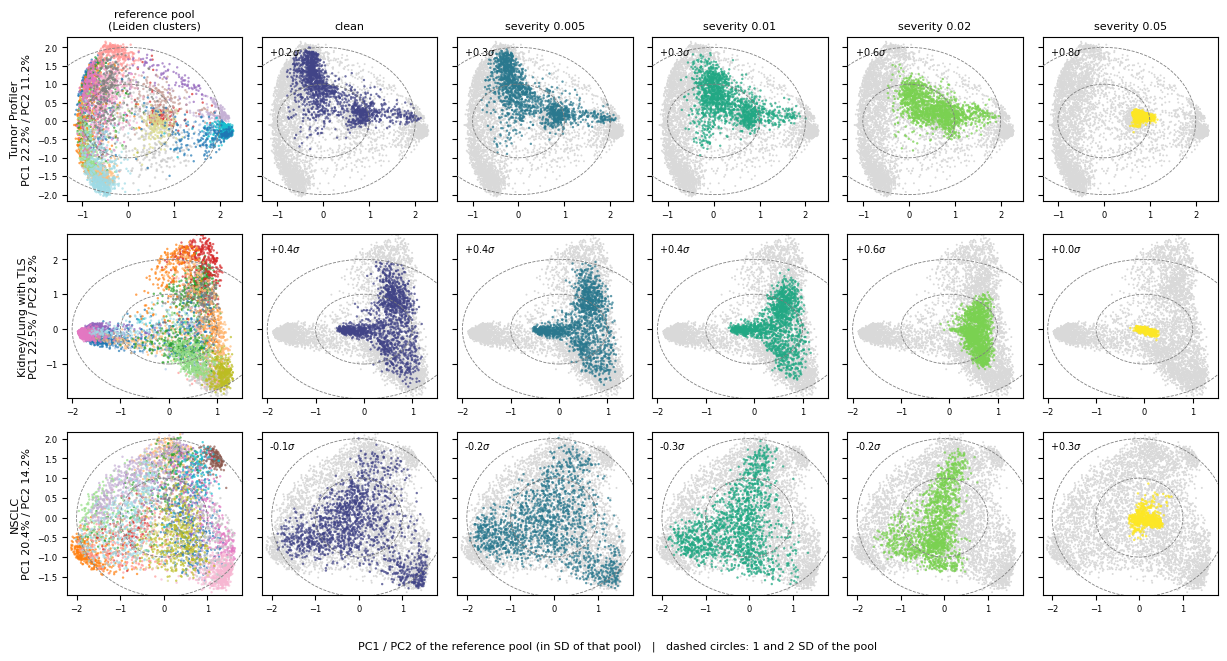

saved -> fig_artifact_pca_control_blur.pdf (+ .png)   [Gaussian blur, pca]


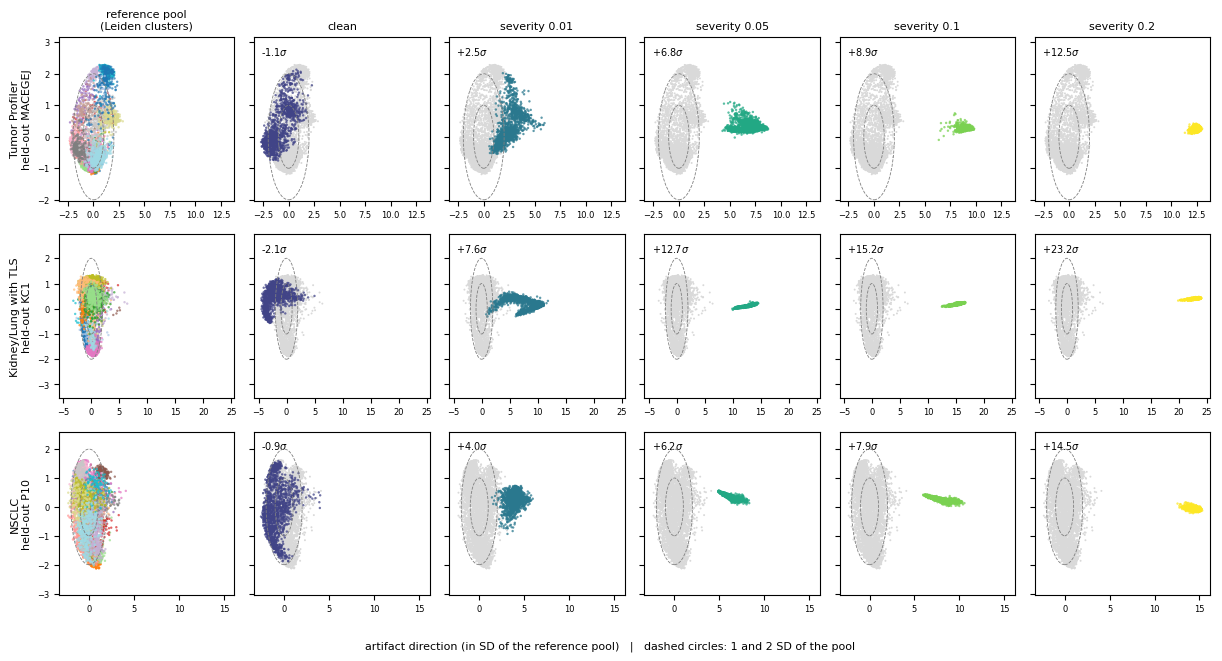

saved -> fig_artifact_drift_plane_saltpepper_sp1-1.pdf (+ .png)   [Salt-and-pepper, 1 px, drift]


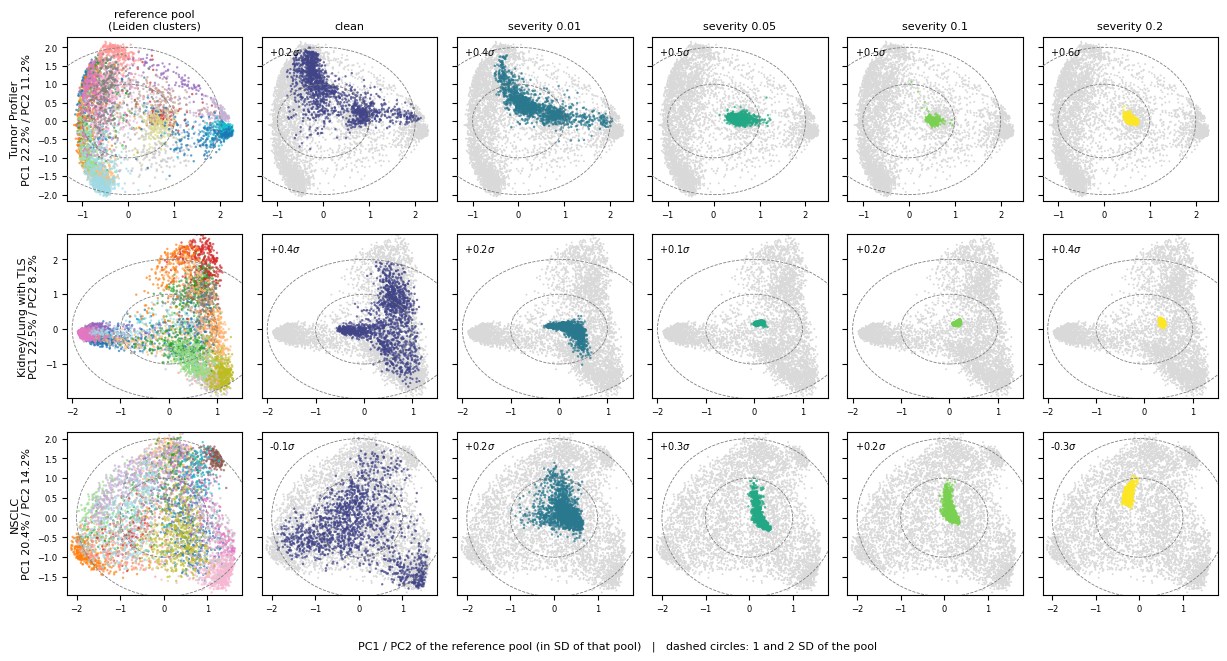

saved -> fig_artifact_pca_control_saltpepper_sp1-1.pdf (+ .png)   [Salt-and-pepper, 1 px, pca]


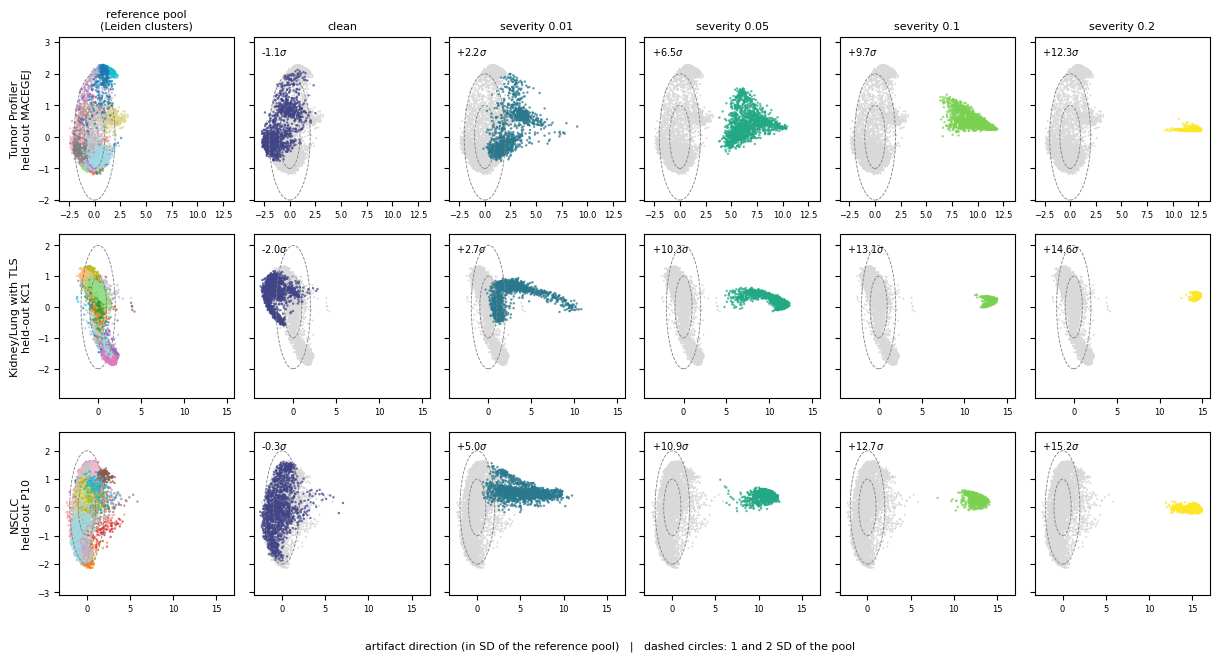

saved -> fig_artifact_drift_plane_saltpepper_sp2-4.pdf (+ .png)   [Salt-and-pepper, 2-4 px, drift]


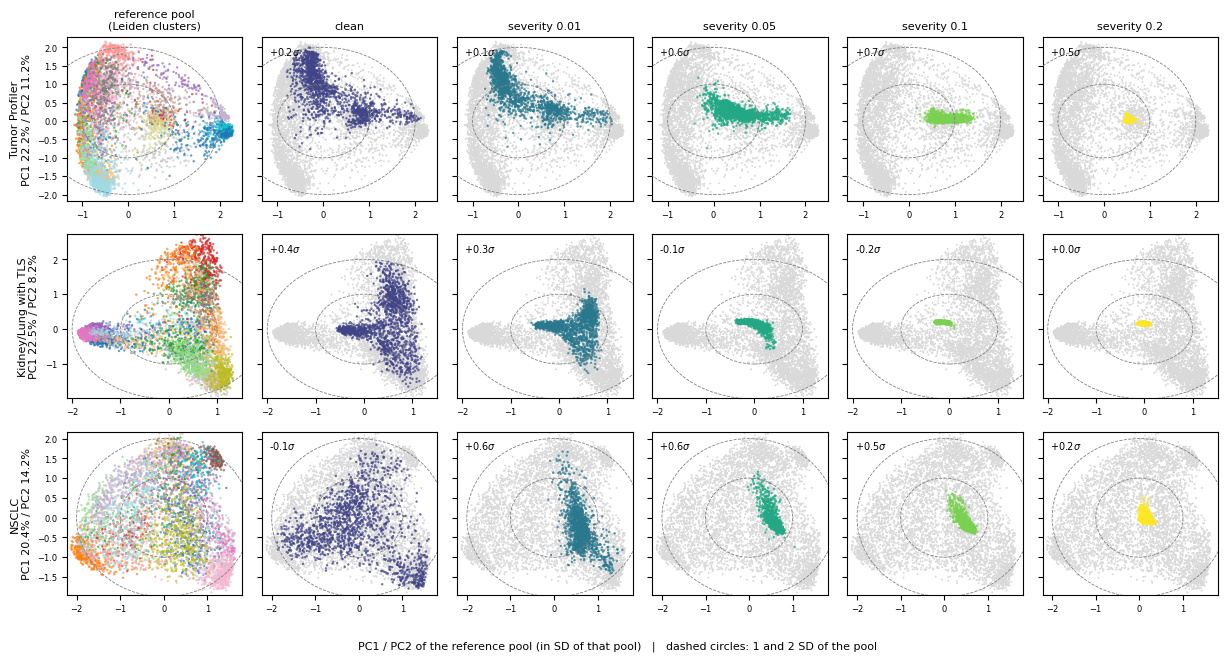

saved -> fig_artifact_pca_control_saltpepper_sp2-4.pdf (+ .png)   [Salt-and-pepper, 2-4 px, pca]

TITLE (LaTeX caption, not in the figure) -- drift plane:
  Drift plane of the patch embeddings, one row per cohort. The horizontal axis is the mean direction along which the artifact displaces the held-out patient, the vertical axis the leading direction of the training pool orthogonal to it; both are scaled by the pool's own standard deviation, so the dashed circles are its 1 and 2 SD contours and the inset number is the mean position of the patient.
TITLE -- PCA control:
  The same spots and the same severity progression on the ordinary PCA plane of the training pool, with no direction chosen to reveal the artifact.

------------------------------------------------------------------------------------------------------------
DRIFT PLANE, x axis = artifact direction: mean position of the patient, in pool sigma
--------------------------------------------------------------------------------

/scratch/slurm-job.9530782/ipykernel_542906/235420725.py:214: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  T = pd.concat(TABS, ignore_index=True) if TABS else pd.DataFrame()


In [ ]:
import time
import torch
import anndata as ad
from sklearn.decomposition import PCA

# ── Settings ──────────────────────────────────────────────────────────────────
FAMS_MAP = [f[0] for f in FAMILIES]   # the 3 families: each gives its 2 figures
N_REF    = 5000        # subsample of the REFERENCE POOL
N_HELD   = 1500        # subsample of the held-out patient (the SAME ones at each severity)
HELD_DONOR = {}        # e.g. {'10x_TuPro': 'MACEGEJ'}; empty -> the first donor found
L2NORM   = True        # same geometry as the kNN module (cosine = L2 after normalization)

STEM_EMB = 'embeddings_radius_factor_0.75_swapxy_True'

def sev_levels(fam):
    return BLUR_LEVELS if fam == 'blur' else SP_LEVELS

def sev_dir(ds, fam, sev):
    """The extraction directory of a level. Severity 0 is ALWAYS the bf0.0 directory (the
    salt-pepper levels have no extracted a=0), so the 3 families share the same clean
    point and their trajectories are directly comparable."""
    base = PROJ / 'patch_embeddings' / ds
    if sev == 0.0:
        return base / f'{STEM_EMB}_blurry_bf0.0'
    if fam == 'blur':
        return base / f'{STEM_EMB}_blurry_bf{sev}'
    return base / f"{STEM_EMB}_saltpepper_a{sev}_sp{fam.split('_sp')[1]}"

def load_emb(d, slides, obs_names):
    """The embeddings of THESE spots, joined by barcode (obs_name = '{barcode}-{slide}')."""
    out = None
    for sl in pd.unique(slides):
        m    = slides == sl
        blob = torch.load(d / f'{sl}.pt', map_location='cpu', weights_only=False)
        e     = blob['embeddings'].float().numpy()
        names = np.asarray(blob['obs_names']).astype(str)
        order = pd.Index(names).get_indexer([n[:-(len(sl) + 1)] for n in obs_names[m]])
        assert (order >= 0).all(), f'barcode mismatch in {d}/{sl}.pt'
        if out is None:
            out = np.empty((len(obs_names), e.shape[1]), dtype=np.float32)
        out[m] = e[order]
    return out.astype(np.float64)

def l2(X):
    return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-12)

# ── Phase 1: what does NOT depend on the family (loaded once only) ────────────
DATA = {}
for ds in DATASETS:
    t0 = time.time()
    # knn_donor_dirs (cell 7) locks the run_tag: no `*` glob at this level, otherwise an
    # another run's tree could supply the leiden cache of a run OTHER than the analyzed one.
    cands = [os.path.join(d, 'leiden_labels.npz') for d in knn_donor_dirs(ds)
             if os.path.exists(os.path.join(d, 'leiden_labels.npz'))]
    if HELD_DONOR.get(ds):
        cands = [c for c in cands if f'donor={HELD_DONOR[ds]}/' in c.replace(os.sep, '/')]
    if not cands:
        print(f'{ds}: no leiden_labels.npz under the analyzed run_tag -> cohort skipped')
        continue
    donor = cands[0].replace(os.sep, '/').split('donor=')[1].split('/')[0]
    z     = np.load(cands[0], allow_pickle=True)
    ref_idx, ref_lab = z['ref_idx'].astype(np.int64), z['labels'].astype(str)

    with open(run_leaf(ds, 'mc') / 'metrics.json') as f:
        adata_path = json.load(f)['input_adata']
    a = ad.read_h5ad(adata_path, backed='r')          # backed: we only read obs
    obs_names_all = np.asarray(a.obs_names).astype(str)
    slide_all     = a.obs['sample_id'].astype(str).to_numpy()
    held_rows     = np.setdiff1d(np.arange(a.n_obs), ref_idx)   # the LOPO fold = all the rest
    del a

    rng = np.random.default_rng(0)
    rs  = rng.choice(len(ref_idx),   size=min(N_REF, len(ref_idx)),   replace=False)
    hs  = rng.choice(len(held_rows), size=min(N_HELD, len(held_rows)), replace=False)
    ref_rows, ref_lab, held_rows = ref_idx[rs], ref_lab[rs], held_rows[hs]

    E_ref = load_emb(sev_dir(ds, 'blur', 0.0), slide_all[ref_rows], obs_names_all[ref_rows])
    if L2NORM:
        E_ref = l2(E_ref)
    DATA[ds] = dict(donor=donor, E_ref=E_ref, ref_lab=ref_lab,
                    held_slides=slide_all[held_rows], held_names=obs_names_all[held_rows])
    print(f'{ds}: held-out {donor} | pool {len(ref_rows)} spots, {len(np.unique(ref_lab))} clusters '
          f'Leiden | patient {len(held_rows)} spots | {time.time()-t0:.0f}s')

def load_family(ds, fam):
    """The patient's embeddings at each severity of THIS family (the clean point is
    shared across families, so reloaded but identical)."""
    d = DATA[ds]
    E = {sev: load_emb(sev_dir(ds, fam, sev), d['held_slides'], d['held_names'])
         for sev in sev_levels(fam)}
    return {s: (l2(e) if L2NORM else e) for s, e in E.items()}

# ── The two planes, both LINEAR (one dot product per point) ───────────────────
def drift_plane(E_ref, E_held):
    """x = artifact direction (mean displacement of the patient between clean and max severity),
    y = principal direction of the pool AFTER removing x (hence orthogonal). Both axes are then
    graduated in POOL STANDARD DEVIATIONS along themselves: the reference cloud therefore has
    standard deviation 1 on both axes, and the patient's position reads directly in sigma."""
    mu = E_ref.mean(0)
    u  = E_held[max(E_held)].mean(0) - E_held[min(E_held)].mean(0)
    u /= np.linalg.norm(u)
    Xr = E_ref - mu
    Xp = Xr - np.outer(Xr @ u, u)                     # the pool, stripped of the artifact direction
    v  = PCA(n_components=1).fit(Xp).components_[0]
    v /= np.linalg.norm(v)
    sx, sy = (Xr @ u).std(), (Xr @ v).std()
    return lambda E: np.c_[((E - mu) @ u) / sx, ((E - mu) @ v) / sy]

def pca_plane(E_ref):
    """The honest control: plain PCA of the pool (PC1/PC2), orienting nothing, graduated in
    the same units. Its explained variance says right away whether a compact cloud is the
    CORRECT result rather than a defect of the figure."""
    mu = E_ref.mean(0)
    p  = PCA(n_components=2).fit(E_ref - mu)
    S  = (E_ref - mu) @ p.components_.T
    return (lambda E: ((E - mu) @ p.components_.T) / S.std(0)), p.explained_variance_ratio_

def panel_grid(kind, fam, HELD):
    """Identical grid for both planes: rows = cohorts, column 0 = the reference pool
    colored by Leiden cluster, following columns = the patient at each severity."""
    levels = sev_levels(fam)
    rows   = [ds for ds in DATASETS if ds in DATA]
    fig, axes = plt.subplots(max(len(rows), 1), 1 + len(levels),
                             figsize=(2.05 * (1 + len(levels)), 2.2 * max(len(rows), 1)),
                             squeeze=False)
    out = []
    for r, ds in enumerate(rows):
        d, E_held = DATA[ds], HELD[ds]
        evr = None
        if kind == 'drift':
            f, ylab = drift_plane(d['E_ref'], E_held), f"{DATASET_LABELS[ds]}\nheld-out {d['donor']}"
        else:
            f, evr = pca_plane(d['E_ref'])
            ylab   = f"{DATASET_LABELS[ds]}\nPC1 {evr[0]:.1%} / PC2 {evr[1]:.1%}"
        P_ref  = f(d['E_ref'])
        P_held = {sev: f(E_held[sev]) for sev in levels}

        for i, lab in enumerate(np.unique(d['ref_lab'])):
            m = d['ref_lab'] == lab
            axes[r][0].scatter(P_ref[m, 0], P_ref[m, 1], s=3, alpha=0.7,
                               color=plt.cm.tab20(i % 20), edgecolors='none')
        axes[r][0].set_ylabel(ylab, fontsize=8)
        if r == 0:
            axes[r][0].set_title('reference pool\n(Leiden clusters)', fontsize=8)

        for j, sev in enumerate(levels, start=1):
            P, ax = P_held[sev], axes[r][j]
            ax.scatter(P_ref[:, 0], P_ref[:, 1], s=2, color='0.85', edgecolors='none')
            ax.scatter(P[:, 0], P[:, 1], s=3, alpha=0.75, edgecolors='none',
                       color=plt.cm.viridis(j / len(levels)))
            ax.text(0.04, 0.95, f'{P[:, 0].mean():+.1f}$\\sigma$', transform=ax.transAxes,
                    fontsize=7, va='top')
            if r == 0:
                ax.set_title('clean' if sev == 0 else f'severity {sev:g}', fontsize=8)
            E0 = E_held[min(levels)]
            # spread = mean distance of the patient's spots to THEIR OWN centroid: if it
            # collapses, all the spots end up on the same embedding (and the prediction can
            # then only be constant). That is the measure of the shrinkage effect.
            out.append(dict(
                dataset=ds, held_donor=d['donor'], corruption=fam, plane=kind,
                severity=float(sev), evr1=(None if evr is None else float(evr[0])),
                evr2=(None if evr is None else float(evr[1])),
                x_sigma=float(P[:, 0].mean()), y_sigma=float(P[:, 1].mean()),
                emb_shift=float(np.linalg.norm(E_held[sev] - E0, axis=1).mean()),
                spread=float(np.linalg.norm(E_held[sev] - E_held[sev].mean(0), axis=1).mean()),
                spread_pool=float(np.linalg.norm(d['E_ref'] - d['E_ref'].mean(0), axis=1).mean())))

        # LIMITS shared by the row, computed on pool UNION patient at ALL severities:
        # bounding them on the pool alone put the patient off-frame as soon as the drift exceeded
        # ~5 sigma. The graduations are kept: the sigma scale IS the message.
        allpts = np.vstack([P_ref] + [P_held[s] for s in levels])
        xlim   = np.percentile(allpts[:, 0], [0.2, 99.8])
        ylim   = np.percentile(allpts[:, 1], [0.2, 99.8])
        pad    = 0.06 * max(xlim[1] - xlim[0], ylim[1] - ylim[0])
        for j, ax in enumerate(axes[r]):
            for rad in (1, 2):
                ax.add_patch(plt.Circle((0, 0), rad, fill=False, color='0.5', lw=0.6, ls='--',
                                        zorder=5))
            ax.set_xlim(xlim[0] - pad, xlim[1] + pad); ax.set_ylim(ylim[0] - pad, ylim[1] + pad)
            ax.tick_params(labelsize=6)
            if j > 0:
                ax.set_yticklabels([])
    return fig, pd.DataFrame(out)

# ── Phase 2: the 2 figures x the 3 families ───────────────────────────────────
TABS = []
for fam, fam_label, _, _ in FAMILIES:
    HELD = {ds: load_family(ds, fam) for ds in DATA}
    for kind, stem_key, xlab in (
            ('drift', 'drift_plane', 'artifact direction (in SD of the reference pool)'),
            ('pca',   'pca_control', 'PC1 / PC2 of the reference pool (in SD of that pool)')):
        fig, tab = panel_grid(kind, fam, HELD)
        fig.supxlabel(f'{xlab}   |   dashed circles: 1 and 2 SD of the pool', fontsize=8, y=0.005)
        fig.tight_layout()
        stem = f'fig_artifact_{stem_key}_{fam}'
        for ext in ('pdf', 'png'):
            fig.savefig(FIGDIR / f'{stem}.{ext}', bbox_inches='tight', dpi=200)
        plt.show()
        print(f'saved -> {stem}.pdf (+ .png)   [{fam_label}, {kind}]')
        TABS.append(tab)          # BOTH planes, otherwise the PCA control has no printed twin
    del HELD

print('\nTITLE (LaTeX caption, not in the figure) -- drift plane:')
print('  Drift plane of the patch embeddings, one row per cohort. The horizontal axis is the mean '
      'direction along which the artifact displaces the held-out patient, the vertical axis the '
      "leading direction of the training pool orthogonal to it; both are scaled by the pool's own "
      'standard deviation, so the dashed circles are its 1 and 2 SD contours and the inset number '
      'is the mean position of the patient.')
print('TITLE -- PCA control:')
print('  The same spots and the same severity progression on the ordinary PCA plane of the '
      'training pool, with no direction chosen to reveal the artifact.')

# ── The printed twins ─────────────────────────────────────────────────────────
T = pd.concat(TABS, ignore_index=True) if TABS else pd.DataFrame()
if len(T):
    for plane, name in (('drift', "DRIFT PLANE, x axis = artifact direction"),
                        ('pca',   'PCA CONTROL, x axis = PC1, y axis = PC2')):
        sub = T[T['plane'] == plane]
        print(f"\n{'-' * 108}\n{name}: mean position of the patient, in pool sigma\n{'-' * 108}")
        print(sub.pivot_table(index=['dataset', 'held_donor', 'corruption'], columns='severity',
                              values=['x_sigma', 'y_sigma']).round(2).to_string())
    ev = T[T['plane'] == 'pca'].groupby('dataset')[['evr1', 'evr2']].first()
    print('\nVariance explained by PC1 and PC2 of the pool:')
    print((ev * 100).round(2).to_string())
    d = T[T['plane'] == 'drift']
    print(f"\n{'-' * 108}\nDISPLACEMENT in the original space (3072d), independent of any "
          f"projection\n{'-' * 108}")
    print(d.pivot_table(index=['dataset', 'corruption'], columns='severity',
                        values='emb_shift').round(3).to_string())
    print('Embeddings L2-normalizes -> reads as a cosine: cos = 1 - emb_shift^2 / 2.')
    print(f"\n{'-' * 108}\nSHRINKAGE: dispersion of the patient around ITS centroid, "
          f"relative to its own point\n{'-' * 108}")
    piv = d.pivot_table(index=['dataset', 'corruption'], columns='severity', values='spread')
    print((piv.div(piv[0.0], axis=0)).round(3).to_string())
    print('\n< 1 = the patient spots shrink together (in the limit, one embedding for all,')
    print('so a constant prediction). Dispersion of the reference pool, for comparison:')
    print(d.groupby('dataset')['spread_pool'].first().round(3).to_string())

## 5. The paper's main figure: one cohort, three panels

The figures of sections 3 and 4 cover all three cohorts and are too large for the body. This one replaces them: **a single cohort, NSCLC, under blur**, in three panels.

**a)** where the embedding goes, on the two linear projections, the pool's plain PCA and the drift plane. The pool in gray, the held-out patient at clean and at the maximum level.

**b)** the predicted uncertainty, each curve referred to its own clean value. Color = estimator, solid line = epistemic, dashed = aleatoric.

**c)** the context: distance to the pool and absolute error as ratios, plus **Pearson as a raw value on a twin axis on the right**. Pearson is not a ratio, so it cannot share the left axis.

The legends are built by hand with `Line2D`: drawn from the curves themselves, the dotted line disappeared behind the markers.

The other figures are not removed. They go to the supplement, where they can stay large.

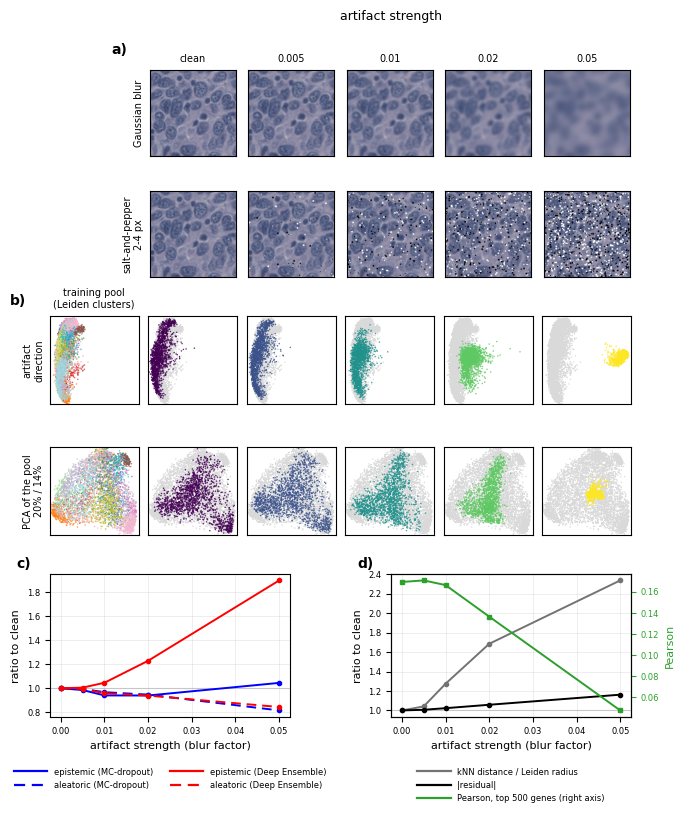

saved -> fig_artifact_summary_LUNG_CANCER.pdf (+ .png)
TITLE (LaTeX caption): NSCLC, artifact strength increasing to the right. (a) one Visium spot of slide MAJOFIJ-1-1 at each level of the two artifacts, Gaussian blur and salt-and-pepper with specks of 2 to 4 pixels. (b) the same held-out patient at each blur level, on two linear projections of the patch embeddings: a plane whose first axis is the mean displacement the artifact causes, above the ordinary PCA plane of the training pool. First column, the training pool alone, colored by its Leiden clusters; in the other columns the pool is gray and the patient carries the color of its severity. The two axes of a tile are scaled independently, so a tile shows where the patient sits, not the shape of the cloud. (c) predicted uncertainty, each curve divided by its own clean value. (d) distance to the training pool and absolute error on the same scale, with the slide-aware Pearson on the right axis, in absolute value. In (c) and (d) every q

In [ ]:
from matplotlib.lines import Line2D
from PIL import Image
from scipy.ndimage import gaussian_filter

# The paper's main figure: ONE cohort, four panels. The three-cohort versions
# stay in sections 3 and 4 and go to the supplement.
DS_MAIN, FAM_MAIN = 'LUNG_CANCER', 'blur'
SEVS_MAIN = sev_levels(FAM_MAIN)
DASH      = (0, (5, 3))     # long dashes, visible on a legend handle with no marker
ZOOM_A    = 1.08            # margin around the cloud in the squares of b); 1.0 = none
# Illustration slide and spot. A slide from THE analyzed cohort, not from TuPro.
ILLU_MAIN = dict(parent=_CFG['datasets']['10x_TuPro']['parent_dir'],
                 slide='MAJOFIJ-1-1', spot=2050, radius_factor=0.75)

# ── The illustration patches, same recipe as section 1 ───────────────────
_meta  = json.load(open(f"{ILLU_MAIN['parent']}meta/{ILLU_MAIN['slide']}.json"))
_diam  = _meta['spot_diameter_fullres']
_rad   = int(round(_diam * ILLU_MAIN['radius_factor']))
_cd    = sc.read_h5ad(f"{ILLU_MAIN['parent']}h5ad/{ILLU_MAIN['slide']}.h5ad")
_cy, _cx = _cd.obs[['x_pixel', 'y_pixel']].to_numpy()[ILLU_MAIN['spot']]      # swap_xy
_img   = np.array(Image.open(f"{ILLU_MAIN['parent']}image/{ILLU_MAIN['slide']}.tif"))
_H, _W = _img.shape[:2]
_pad   = 4 * _rad
_y0, _y1 = max(0, int(_cy) - _pad), min(_H, int(_cy) + _pad)
_x0, _x1 = max(0, int(_cx) - _pad), min(_W, int(_cx) + _pad)
_win = _img[_y0:_y1, _x0:_x1].copy()
_wcy, _wcx = int(_cy) - _y0, int(_cx) - _x0
del _img

def _patch(w):
    p = _crop_spot_patch(w, _wcx, _wcy, _rad, w.shape[1], w.shape[0])
    return np.asarray(resize_crop(Image.fromarray(p)))

_clean = _patch(_win)

def patch_at(kind, lev):
    """The 224 patch at this level. The blur is applied to the window before cropping, the
    salt-and-pepper to the 224 patch, exactly as at extraction."""
    if kind == 'blur':
        if lev == 0:
            return _clean
        w = _win.copy()
        for ch in range(3):
            w[..., ch] = np.clip(gaussian_filter(_win[..., ch].astype(np.float32),
                                                 sigma=lev * _diam), 0, 255).astype(np.uint8)
        return _patch(w)
    p = _clean.copy()
    if lev > 0:
        apply_salt_pepper(p, lev, 0.5, np.random.default_rng((0, ILLU_MAIN['spot'])),
                          speck_min=2, speck_max=4)
    return p

# ── Data for the projections ─────────────────────────────────────────────────────
d    = DATA[DS_MAIN]
HELD = load_family(DS_MAIN, FAM_MAIN)
f_pca, evr = pca_plane(d['E_ref'])
f_drift    = drift_plane(d['E_ref'], HELD)

# n+1 columns: the first carries the reference pool alone, as in the figure of
# section 4; the next n carry one severity each. The patches of a) are shifted
# by one column to fall under the corresponding severities of b).
n   = len(SEVS_MAIN)
fig = plt.figure(figsize=(7.5, 8.4))
gs  = fig.add_gridspec(5, 2 * (n + 1), height_ratios=[0.9, 0.9, 1.0, 1.0, 1.5],
                       hspace=0.35, wspace=0.25)
# Severity reads left to right on the four rows of thumbnails: a single label,
# above, rather than a repeated axis.
fig.text(0.58, 0.94, 'artifact strength', ha='center', fontsize=9)

# ── a) what the artifact looks like: one row per artifact, one salt-pepper variant ───────
for r, (kind, levels, rowlab) in enumerate((('blur', BLUR_LEVELS, 'Gaussian blur'),
                                            ('sp',   SP_LEVELS,   'salt-and-pepper\n2-4 px'))):
    for j, lev in enumerate(levels):
        ax = fig.add_subplot(gs[r, 2 * (j + 1):2 * (j + 1) + 2])
        ax.imshow(patch_at(kind, lev))
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_box_aspect(1)
        if r == 0:
            ax.set_title('clean' if lev == 0 else f'{lev:g}', fontsize=7)
        if j == 0:
            ax.set_ylabel(rowlab, fontsize=7)
            if r == 0:
                ax.text(-0.45, 1.32, 'a)', transform=ax.transAxes, fontsize=10,
                        fontweight='bold', va='top', ha='left')

# ── b) where the embedding goes: the same grid as section 4, smaller ─────────
# Column 0: the reference pool alone, colored by Leiden cluster. Following columns: the
# pool in gray and the patient at this severity. Without the 1 and 2 sigma circles or the
# position annotation, which made reading heavier at this size.
lab_order = np.unique(d['ref_lab'])
for r, (f, rowlab) in enumerate(((f_drift, 'artifact\ndirection'),
                                 (f_pca,   f'PCA of the pool\n{evr[0]:.0%} / {evr[1]:.0%}')),
                                start=2):
    P_ref = f(d['E_ref'])
    P     = {s: f(HELD[s]) for s in SEVS_MAIN}
    allp  = np.vstack([P_ref] + [P[s] for s in SEVS_MAIN])
    # Bounds taken SEPARATELY on each axis: the cloud then fills the thumbnail. Forcing the
    # same half-side on both left a wide white band on the shorter axis. The
    # thumbnail stays square (set_box_aspect), so the two axes do not have the same scale: the
    # caption says so.
    xl, yl = np.percentile(allp[:, 0], [0.2, 99.8]), np.percentile(allp[:, 1], [0.2, 99.8])
    hx, hy = ZOOM_A * 0.5 * (xl[1] - xl[0]), ZOOM_A * 0.5 * (yl[1] - yl[0])
    cx, cy = (xl[0] + xl[1]) / 2, (yl[0] + yl[1]) / 2

    row_axes = []
    ax0 = fig.add_subplot(gs[r, 0:2])                            # column 0: the pool alone
    row_axes.append(ax0)
    for i, lab in enumerate(lab_order):
        m = d['ref_lab'] == lab
        ax0.scatter(P_ref[m, 0], P_ref[m, 1], s=1.2, edgecolors='none', alpha=0.7,
                    color=plt.cm.tab20(i % 20))
    ax0.set_ylabel(rowlab, fontsize=7)
    if r == 2:
        ax0.set_title('training pool\n(Leiden clusters)', fontsize=7)
        ax0.text(-0.45, 1.25, 'b)', transform=ax0.transAxes, fontsize=10,
                 fontweight='bold', va='top', ha='left')
    for j, sev in enumerate(SEVS_MAIN):                          # the patient, one column per level
        ax = fig.add_subplot(gs[r, 2 * (j + 1):2 * (j + 1) + 2])
        row_axes.append(ax)
        ax.scatter(P_ref[:, 0], P_ref[:, 1], s=1.0, color='0.85', edgecolors='none')
        ax.scatter(P[sev][:, 0], P[sev][:, 1], s=1.2, edgecolors='none', alpha=0.8,
                   color=plt.cm.viridis(j / max(n - 1, 1)))
    for ax in row_axes:                                          # same framing across the whole row
        ax.set_xlim(cx - hx, cx + hx); ax.set_ylim(cy - hy, cy + hy)
        ax.set_box_aspect(1)
        ax.set_xticks([]); ax.set_yticks([])

# ── c) and d): the dose-responses of THIS cohort ──────────────────────────────
# Sub-grid specific to the last row: its wspace must be wider than that of the
# thumbnails, otherwise the left axis of d) bites into c).
_gs_bot = gs[4, :].subgridspec(1, 2, wspace=0.42)
axC = fig.add_subplot(_gs_bot[0])
axD = fig.add_subplot(_gs_bot[1])

def curve(df, col):
    g = ratio_curve(df, col)
    return (None, None) if g is None else (g['severity'].to_numpy(), g['ratio'].to_numpy())

# EVERYTHING WITH A GENE AXIS is read on the N_TOP best-predicted genes on the clean image, not
# on the 3000 HVGs: the mean over the whole panel is pulled down by the genes the
# model does not predict, even without an artifact. The ranking comes from MC-dropout severity 0
# and serves BOTH methods, so the gene set is the same. The kNN distance itself has
# no gene axis: it stays computed over all spots.
N_TOP = 500
pgm   = load_per('per_gene', methods=('mc', 'ensemble'), verbose=False)
pgm   = pgm[(pgm['dataset'] == DS_MAIN) & (pgm['corruption'] == FAM_MAIN)]
top   = (pgm[(pgm['method'] == 'mc') & (pgm['severity'] == 0.0)]
         .groupby('gene')['pearson'].mean().sort_values(ascending=False).head(N_TOP).index)
sel   = pgm[pgm['gene'].isin(top)]
# mean over the retained genes and over the folds, at each (method, severity)
G_AGG = {m: (sel[sel['method'] == m]
             .groupby('severity')[['epistemic', 'aleatoric', 'abs_resid', 'pearson']]
             .mean().reset_index())
         for m in ('mc', 'ensemble')}

for m, sub in G_AGG.items():
    for col, ls in (('epistemic', '-'), ('aleatoric', DASH)):
        x, y = curve(sub, col)
        if x is not None:
            axC.plot(x, y, ls=ls, color=METHOD_COLORS[m], marker='o', ms=3, lw=1.4)
axC.axhline(1.0, color='0.8', lw=0.8, zorder=0)
axC.set_ylabel('ratio to clean', fontsize=8)
# LEGEND WITHOUT MARKER. A dot in the middle of the handle cuts the dashed line and makes it read
# like a solid line: the marker is what must be removed, not the handle lengthened.
axC.legend(handles=[Line2D([], [], color=METHOD_COLORS[m], ls=ls, lw=1.6,
                           label=f'{lab} ({METHOD_LABELS[m]})')
                    for m in ('mc', 'ensemble')
                    for ls, lab in (('-', 'epistemic'), (DASH, 'aleatoric'))],
           fontsize=6, frameon=False, handlelength=4.0, ncol=2,
           loc='upper center', bbox_to_anchor=(0.5, -0.30))

ksub = knn[(knn['dataset'] == DS_MAIN) & (knn['corruption'] == FAM_MAIN)]
for df, col, color in ((ksub, KNN_SIG, '0.45'), (G_AGG['mc'], 'abs_resid', 'k')):
    x, y = curve(df, col)
    if x is not None:
        axD.plot(x, y, '-', color=color, marker='o', ms=3, lw=1.4)
axD.axhline(1.0, color='0.8', lw=0.8, zorder=0)
axD.set_ylabel('ratio to clean', fontsize=8)
# Pearson is not a ratio: twin axis on the right, raw value, on the same genes.
axP = axD.twinx()
p   = G_AGG['mc'].set_index('severity')['pearson'].sort_index()
axP.plot(p.index, p.to_numpy(), '-', color='#2ca02c', marker='s', ms=3, lw=1.4)
axP.set_ylabel('Pearson', fontsize=8, color='#2ca02c')
axP.tick_params(axis='y', labelsize=6, colors='#2ca02c')
axD.legend(handles=[Line2D([], [], color='0.45', lw=1.6, label='kNN distance / Leiden radius'),
                    Line2D([], [], color='k', lw=1.6, label='|residual|'),
                    Line2D([], [], color='#2ca02c', lw=1.6,
                           label=f'Pearson, top {N_TOP} genes (right axis)')],
           fontsize=6, frameon=False, handlelength=4.0, ncol=1,
           loc='upper center', bbox_to_anchor=(0.5, -0.30))

for ax, lab in ((axC, 'c'), (axD, 'd')):
    ax.grid(alpha=0.25, lw=0.6)
    ax.tick_params(labelsize=6)
    ax.set_xlabel('artifact strength (blur factor)', fontsize=8)
    ax.text(-0.14, 1.12, f'{lab})', transform=ax.transAxes, fontsize=10, fontweight='bold',
            va='top', ha='left')

stem = f'fig_artifact_summary_{DS_MAIN}'
for ext in ('pdf', 'png'):
    fig.savefig(FIGDIR / f'{stem}.{ext}', bbox_inches='tight', dpi=300)
plt.show()
print(f'saved -> {stem}.pdf (+ .png)')
print(f"TITLE (LaTeX caption): {DATASET_LABELS[DS_MAIN]}, artifact strength increasing to the "
      f"right. (a) one Visium spot of slide {ILLU_MAIN['slide']} at each level of the two "
      'artifacts, Gaussian blur and salt-and-pepper with specks of 2 to 4 pixels. (b) the same '
      'held-out patient at each blur level, on two linear projections of the patch embeddings: '
      'a plane whose first axis is the mean displacement the artifact causes, above the ordinary '
      'PCA plane of the training pool. First column, the training pool alone, colored by its '
      'Leiden clusters; in the other columns the pool is gray and the patient carries the color '
      'of its severity. The two axes of a tile are scaled independently, so a tile shows where '
      'the patient sits, not the shape of the cloud. (c) predicted uncertainty, each curve '
      'divided by its own clean value. '
      f'(d) distance to the training pool and absolute error on the same scale, with the '
      f'slide-aware Pearson on the right axis, in absolute value. In (c) and (d) every quantity '
      f'that has a gene axis is restricted to the {N_TOP} genes best predicted on the clean '
      f'image, ranked once on the held-out donors; the kNN distance has no gene axis and uses '
      f'every spot. All curves are averaged over the held-out donors of the cohort.')

print('\nFigure numbers:')
print(pd.concat([G_AGG['mc'].set_index('severity').add_suffix('_mc'),
                 G_AGG['ensemble'].set_index('severity')[['epistemic', 'aleatoric']]
                 .add_suffix('_ens'),
                 ksub.groupby('severity')[[KNN_SIG]].mean()], axis=1).round(4).to_string())
del HELD, _win

## 6. The supplement: the same curves, three cohorts, two artifacts

The body figure shows only one cohort. The subsection text, however, quotes numbers for all three, and two of them go the other way on Kidney/Lung TLS: aleatoric rises there under blur, and the ensemble falls there under salt-and-pepper.

This figure therefore carries panels c) and d) for all three cohorts and both artifacts. Four rows in pairs, uncertainty above context, blur then salt-and-pepper. Three columns, one per cohort.

Same restriction as in the body: everything with a gene axis is read on the 500 best-predicted genes **of that cohort**, ranked on its own clean-image result. The kNN distance has no gene axis and uses all spots.

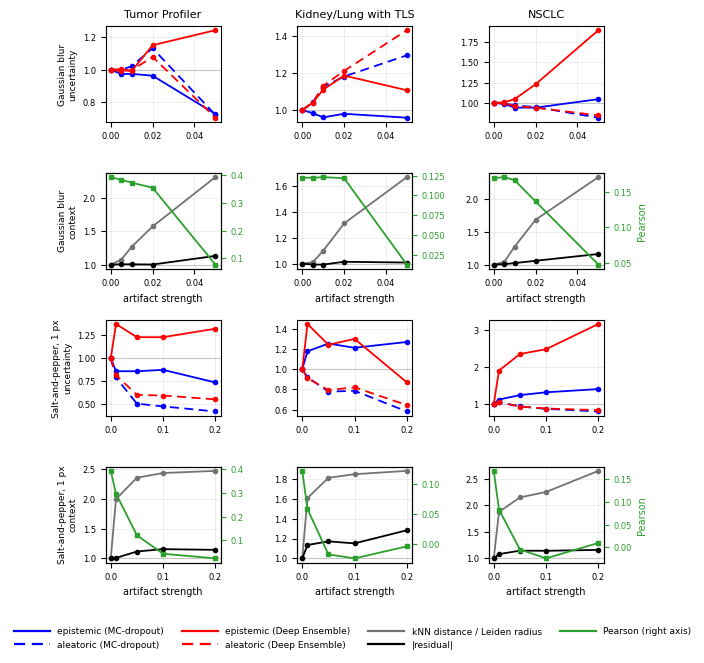

saved -> fig_artifact_supplement_all_cohorts.pdf (+ .png)
TITLE (LaTeX caption): The two lower panels of the main artifact figure, for the three cohorts and the two artifacts. Rows come in pairs, uncertainty above context, first for Gaussian blur then for salt-and-pepper. Every quantity with a gene axis is restricted to the 500 genes best predicted on the clean image of that cohort; the kNN distance uses every spot. Curves and colors as in the main figure.

EPISTEMIC -- ratio to the clean value
severity                               0.000  0.005  0.010  0.020  0.050  0.100  0.200
corruption       dataset     method                                                   
blur             10x_TuPro   ensemble    1.0  1.004  0.992  1.151  1.244    NaN    NaN
                             mc          1.0  0.974  0.975  0.963  0.727    NaN    NaN
                 LUNG_CANCER ensemble    1.0  1.005  1.046  1.230  1.900    NaN    NaN
                             mc          1.0  0.985  0.940  0.940

In [ ]:
from matplotlib.lines import Line2D

# Supplement: panels c) and d) of the body figure, for all THREE cohorts and
# BOTH artifacts. Same per-gene restriction, same aggregation, only the scope changes.
FAMS_SUP = ['blur', 'saltpepper_sp1-1']
N_TOP_SUP = 500

pg_sup = load_per('per_gene', methods=('mc', 'ensemble'), verbose=False)
if len(pg_sup) == 0 or 'pearson' not in pg_sup.columns:
    print("per_gene parquet with no pearson column: rerun the precompute.")
else:
    # Smaller than the body figure, which is 7.5 x 8.4: this is a supplement.
    nrow = 2 * len(FAMS_SUP)
    fig, axes = plt.subplots(nrow, len(DATASETS), figsize=(6.3, 1.45 * nrow + 0.7),
                             squeeze=False)
    rows_tab = []
    for fi, fam in enumerate(FAMS_SUP):
        fam_label = next(f[1] for f in FAMILIES if f[0] == fam)
        for c, ds in enumerate(DATASETS):
            sub_pg = pg_sup[(pg_sup['dataset'] == ds) & (pg_sup['corruption'] == fam)]
            if sub_pg.empty:
                axes[2 * fi][c].set_axis_off(); axes[2 * fi + 1][c].set_axis_off()
                continue
            # Ranking per cohort, on its own clean Pearson, MC-dropout; it serves
            # both methods so the gene set is the same.
            top = (sub_pg[(sub_pg['method'] == 'mc') & (sub_pg['severity'] == 0.0)]
                   .groupby('gene')['pearson'].mean()
                   .sort_values(ascending=False).head(N_TOP_SUP).index)
            g_agg = {m: (sub_pg[(sub_pg['method'] == m) & (sub_pg['gene'].isin(top))]
                         .groupby('severity')[['epistemic', 'aleatoric', 'abs_resid', 'pearson']]
                         .mean().reset_index())
                     for m in ('mc', 'ensemble')}

            axU, axX = axes[2 * fi][c], axes[2 * fi + 1][c]
            for m, t in g_agg.items():
                for col, ls in (('epistemic', '-'), ('aleatoric', DASH)):
                    gg = ratio_curve(t, col)
                    if gg is not None:
                        axU.plot(gg['severity'], gg['ratio'], ls=ls, color=METHOD_COLORS[m],
                                 marker='o', ms=3, lw=1.3)
            ks = knn[(knn['dataset'] == ds) & (knn['corruption'] == fam)]
            for t, col, color in ((ks, KNN_SIG, '0.45'), (g_agg['mc'], 'abs_resid', 'k')):
                gg = ratio_curve(t, col)
                if gg is not None:
                    axX.plot(gg['severity'], gg['ratio'], '-', color=color, marker='o',
                             ms=3, lw=1.3)
            axP = axX.twinx()
            p = g_agg['mc'].set_index('severity')['pearson'].sort_index()
            axP.plot(p.index, p.to_numpy(), '-', color='#2ca02c', marker='s', ms=3, lw=1.3)
            axP.tick_params(axis='y', labelsize=6, colors='#2ca02c')
            if c == len(DATASETS) - 1:
                axP.set_ylabel('Pearson', fontsize=7, color='#2ca02c')

            for ax in (axU, axX):
                ax.axhline(1.0, color='0.8', lw=0.8, zorder=0)
                ax.grid(alpha=0.25, lw=0.6)
                ax.tick_params(labelsize=6)
            if fi == 0:
                axes[0][c].set_title(DATASET_LABELS[ds], fontsize=8)
            if c == 0:
                axU.set_ylabel(f'{fam_label}\nuncertainty', fontsize=6.5)
                axX.set_ylabel(f'{fam_label}\ncontext', fontsize=6.5)
            axX.set_xlabel('artifact strength', fontsize=7)
            for m, t in g_agg.items():
                rows_tab.append(t.assign(dataset=ds, corruption=fam, method=m))

    h = [Line2D([], [], color=METHOD_COLORS[m], ls=ls, lw=1.6, label=f'{lab} ({METHOD_LABELS[m]})')
         for m in ('mc', 'ensemble') for ls, lab in (('-', 'epistemic'), (DASH, 'aleatoric'))]
    h += [Line2D([], [], color='0.45', lw=1.6, label='kNN distance / Leiden radius'),
          Line2D([], [], color='k', lw=1.6, label='|residual|'),
          Line2D([], [], color='#2ca02c', lw=1.6, label='Pearson (right axis)')]
    fig.legend(handles=h, fontsize=6.5, frameon=False, handlelength=4.0, ncol=4,
               loc='lower center', bbox_to_anchor=(0.5, -0.02))
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    stem = 'fig_artifact_supplement_all_cohorts'
    for ext in ('pdf', 'png'):
        fig.savefig(FIGDIR / f'{stem}.{ext}', bbox_inches='tight', dpi=300)
    plt.show()
    print(f'saved -> {stem}.pdf (+ .png)')
    print(f'TITLE (LaTeX caption): The two lower panels of the main artifact figure, for the '
          f'three cohorts and the two artifacts. Rows come in pairs, uncertainty above context, '
          f'first for Gaussian blur then for salt-and-pepper. Every quantity with a gene axis is '
          f'restricted to the {N_TOP_SUP} genes best predicted on the clean image of that cohort; '
          f'the kNN distance uses every spot. Curves and colors as in the main figure.')

    T11 = pd.concat(rows_tab, ignore_index=True)
    for q in ('epistemic', 'aleatoric', 'abs_resid'):
        piv = T11.pivot_table(index=['corruption', 'dataset', 'method'], columns='severity',
                              values=q)
        print(f'\n{q.upper()} -- ratio to the clean value')
        print(piv.div(piv[0.0], axis=0).round(3).to_string())
    print('\nPEARSON -- raw value')
    print(T11[T11['method'] == 'mc']
          .pivot_table(index=['corruption', 'dataset'], columns='severity', values='pearson')
          .round(4).to_string())